# Tugas: Klasifikasi Sentimen Komentar TikTok tentang Program MBG dengan SVM
**Kasus:** klasifikasi (3 kelas: Positif, Netral, Negatif)  
**Algoritma:** Support Vector Machine (SVM) — karena NIM genap  
**Dataset:** `mbg_tiktok_comment_300.csv` (300 komentar TikTok tentang program Makan Bergizi Gratis)

> Isi **Nama / NIM** Anda di sini: ........................

## 1. Import Library

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 200)

## 2. Memuat & Memahami Data

In [2]:
# Jika memakai Google Colab: upload file CSV dulu (ikon folder di sebelah kiri)
df = pd.read_csv('mbg_tiktok_comment_300.csv')
print('Ukuran data (baris, kolom):', df.shape)
df.head()

Ukuran data (baris, kolom): (300, 3)


,id,komentar,sentimen
0,247,Banyak siswa mengikuti MBG,Netral
1,83,Program yang sangat bermanfaat,Positif
2,192,Porsinya terlalu sedikit,Negatif
3,300,Saya melihat pembagian MBG,Netral
4,35,Kualitas makanan bagus,Positif


In [3]:
df.info()
print()
print('Missing value per kolom:\n', df.isna().sum())
print('\nBaris duplikat penuh      :', df.duplicated().sum())
print('Jumlah id unik            :', df['id'].nunique())
print('Jumlah komentar unik      :', df['komentar'].nunique())
print('\nDistribusi kelas:\n', df['sentimen'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        300 non-null    int64
 1   komentar  300 non-null    str  
 2   sentimen  300 non-null    str  
dtypes: int64(1), str(2)
memory usage: 7.2 KB

Missing value per kolom:
 id          0
komentar    0
sentimen    0
dtype: int64

Baris duplikat penuh      : 0
Jumlah id unik            : 300
Jumlah komentar unik      : 30

Distribusi kelas:
 sentimen
Netral     100
Positif    100
Negatif    100
Name: count, dtype: int64


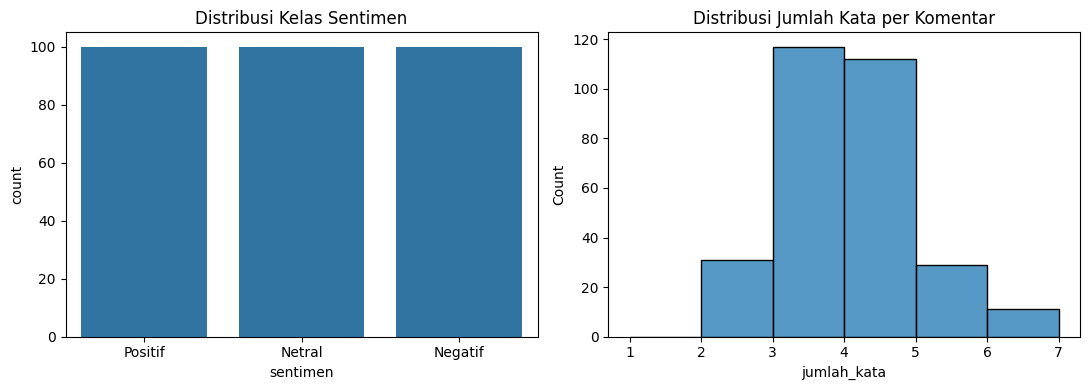

sentimen
Negatif    10
Netral     10
Positif    10
Name: komentar, dtype: int64

In [4]:
# Visualisasi distribusi kelas & panjang komentar
df['jumlah_kata'] = df['komentar'].str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='sentimen', order=['Positif','Netral','Negatif'], ax=ax[0])
ax[0].set_title('Distribusi Kelas Sentimen')
sns.histplot(df['jumlah_kata'], bins=range(1,8), ax=ax[1])
ax[1].set_title('Distribusi Jumlah Kata per Komentar')
plt.tight_layout(); plt.show()
df.groupby('sentimen')['komentar'].nunique()

**Catatan pemahaman data:** dataset seimbang (100 komentar per kelas), tidak ada missing value, namun hanya ada **30 kalimat komentar unik** (10 per kelas) yang berulang-ulang. Hal ini penting dan akan dibahas pada tahap evaluasi (risiko *data leakage*).

## 3. Jenis Data Berdasarkan Jenis Pengukuran

In [5]:
jenis = pd.DataFrame({
    'Fitur': ['id', 'komentar', 'sentimen'],
    'Tipe di pandas': [str(df[c].dtype) for c in ['id','komentar','sentimen']],
    'Skala pengukuran': ['Nominal (pengenal/identitas)', 'Nominal (data teks / kategorikal)', 'Nominal (label kelas; target)'],
    'Peran': ['Tidak dipakai (bukan fitur prediktif)', 'Fitur (X)', 'Target (y)']
})
jenis

,Fitur,Tipe di pandas,Skala pengukuran,Peran
0,id,int64,Nominal (pengenal/identitas),Tidak dipakai (bukan fitur prediktif)
1,komentar,str,Nominal (data teks / kategorikal),Fitur (X)
2,sentimen,str,Nominal (label kelas; target),Target (y)


## 4. Pemrosesan Data (Preprocessing)
Tahapan yang dilakukan beserta alasannya:

| No | Tahap | Alasan |
|----|-------|--------|
| 1 | Hapus kolom `id` | Hanya nomor urut/pengenal, tidak mengandung informasi sentimen; bila dipakai justru menimbulkan noise. |
| 2 | Cek missing value | Memastikan kualitas data. Komentar identik dipertahankan karena berasal dari pengguna berbeda. |
| 3 | *Case folding* (huruf kecil) | "Program" dan "program" harus dianggap kata yang sama. |
| 4 | Pembersihan teks (hapus angka, tanda baca, emoji, URL, spasi berlebih) | Menghilangkan karakter yang tidak membawa makna sentimen. |
| 5 | Tokenisasi | Memecah kalimat menjadi kata agar dapat dihitung. |
| 6 | *Stopword removal* (kustom) | Membuang kata umum tanpa makna sentimen. Kata negasi (*tidak, kurang, belum*) **sengaja dipertahankan** karena mengubah makna. |
| 7 | *Label encoding* pada target | SVM membutuhkan target numerik. |
| 8 | Ekstraksi fitur TF-IDF | SVM hanya menerima angka; TF-IDF mengubah teks menjadi vektor numerik berbobot. |
| 9 | Pembagian data latih/uji | Untuk menguji model pada data yang tidak dipakai saat pelatihan. |

In [6]:
# 1-2. Hapus kolom id & missing value.
# Komentar identik TIDAK dibuang: tiap baris adalah komentar dari pengguna berbeda (id berbeda).
data = df.drop(columns=['id', 'jumlah_kata']).copy()
data = data.dropna().reset_index(drop=True)
data['komentar'] = data['komentar'].astype(str)
print('Ukuran setelah cleaning awal:', data.shape)

Ukuran setelah cleaning awal: (300, 2)


In [7]:
# 3-6. Case folding, cleaning, tokenisasi, stopword removal
# Stopword kustom; kata negasi (tidak, kurang, belum, bukan) TIDAK dibuang
stopwords_id = {'yang','dan','di','ke','dari','ini','itu','untuk','pada','dengan','atas',
                'kami','saya','ada','sudah','sedang','akan','juga','adalah','oleh','nya'}

def preprocess(teks):
    teks = teks.lower()                                   # case folding
    teks = re.sub(r'http\S+|www\.\S+', ' ', teks)         # hapus URL
    teks = re.sub(r'[^a-z\s]', ' ', teks)                 # hapus angka, tanda baca, emoji
    teks = re.sub(r'\s+', ' ', teks).strip()              # rapikan spasi
    tokens = teks.split()                                  # tokenisasi
    tokens = [t for t in tokens if t not in stopwords_id]  # stopword removal
    return ' '.join(tokens)

data['komentar_bersih'] = data['komentar'].apply(preprocess)

# 7. Label encoding
le = LabelEncoder()
data['label'] = le.fit_transform(data['sentimen'])
print('Pemetaan label:', dict(zip(le.classes_, le.transform(le.classes_))))

Pemetaan label: {'Negatif': np.int64(0), 'Netral': np.int64(1), 'Positif': np.int64(2)}


### Hasil Pemrosesan Data — 5 Data Teratas dan 5 Data Terbawah

In [8]:
kolom = ['komentar', 'komentar_bersih', 'sentimen', 'label']
print('=== 5 DATA TERATAS ===')
display(data[kolom].head(5))
print('=== 5 DATA TERBAWAH ===')
display(data[kolom].tail(5))

=== 5 DATA TERATAS ===


,komentar,komentar_bersih,sentimen,label
0,Banyak siswa mengikuti MBG,banyak siswa mengikuti mbg,Netral,1
1,Program yang sangat bermanfaat,program sangat bermanfaat,Positif,2
2,Porsinya terlalu sedikit,porsinya terlalu sedikit,Negatif,0
3,Saya melihat pembagian MBG,melihat pembagian mbg,Netral,1
4,Kualitas makanan bagus,kualitas makanan bagus,Positif,2


=== 5 DATA TERBAWAH ===


,komentar,komentar_bersih,sentimen,label
295,Terima kasih atas program MBG,terima kasih program mbg,Positif,2
296,Kualitas makanan bagus,kualitas makanan bagus,Positif,2
297,Informasi sudah diumumkan,informasi diumumkan,Netral,1
298,Distribusinya sudah baik,distribusinya baik,Positif,2
299,Porsinya terlalu sedikit,porsinya terlalu sedikit,Negatif,0


### Ekstraksi Fitur TF-IDF
Hasil TF-IDF (5 teratas dan 5 terbawah) juga ditampilkan sebagai data akhir hasil pemrosesan yang masuk ke model.

In [9]:
tfidf = TfidfVectorizer(ngram_range=(1, 2))   # unigram + bigram agar frasa seperti 'tidak suka' tertangkap
X_all = tfidf.fit_transform(data['komentar_bersih'])
y_all = data['label'].values
print('Bentuk matriks TF-IDF:', X_all.shape)

tfidf_df = pd.DataFrame(X_all.toarray(), columns=tfidf.get_feature_names_out())
tfidf_df['label'] = y_all
print('\n=== 5 TERATAS (TF-IDF; 10 kolom pertama + label) ===')
display(tfidf_df.iloc[:5, list(range(10)) + [-1]])
print('=== 5 TERBAWAH (TF-IDF; 10 kolom pertama + label) ===')
display(tfidf_df.iloc[-5:, list(range(10)) + [-1]])

Bentuk matriks TF-IDF: (300, 123)

=== 5 TERATAS (TF-IDF; 10 kolom pertama + label) ===


,anak,anak sekolah,anak senang,anak tidak,ayam,bagus,baik,banyak,banyak makanan,banyak siswa,label
0,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.352923,0.0,0.401978,1
1,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,0.000000,2
2,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,0.000000,0
3,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,0.000000,1
4,0.0,0.0,0.0,0.0,0.0,0.50651,0.0,0.000000,0.0,0.000000,2


=== 5 TERBAWAH (TF-IDF; 10 kolom pertama + label) ===


,anak,anak sekolah,anak senang,anak tidak,ayam,bagus,baik,banyak,banyak makanan,banyak siswa,label
295,0.0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,2
296,0.0,0.0,0.0,0.0,0.0,0.50651,0.000000,0.0,0.0,0.0,2
297,0.0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,1
298,0.0,0.0,0.0,0.0,0.0,0.00000,0.558283,0.0,0.0,0.0,2
299,0.0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0.0,0


## 5. Klasifikasi dengan SVM
### 5a. Skenario 1 — Pembagian acak biasa (stratified 80:20)

In [10]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    data['komentar_bersih'], y_all, test_size=0.2, random_state=42, stratify=y_all)

vec = TfidfVectorizer(ngram_range=(1, 2))
X_train = vec.fit_transform(X_train_txt)   # fit hanya pada data latih
X_test = vec.transform(X_test_txt)

svm = SVC(kernel='linear', C=1.0, random_state=42)
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)

print('Akurasi :', round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

Akurasi : 1.0
              precision    recall  f1-score   support

     Negatif       1.00      1.00      1.00        20
      Netral       1.00      1.00      1.00        20
     Positif       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



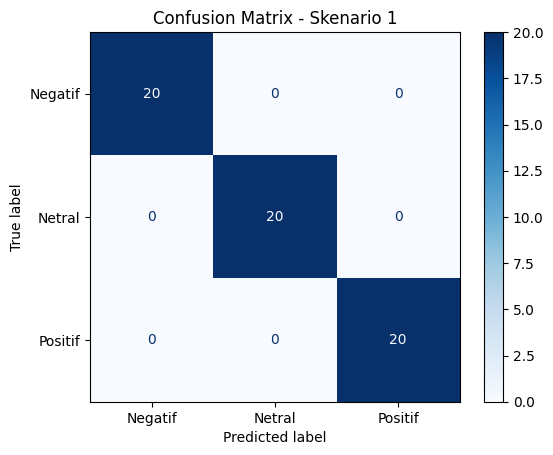

In [11]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_).plot(cmap='Blues')
plt.title('Confusion Matrix - Skenario 1'); plt.show()

### 5b. Skenario 2 — Pembagian berdasarkan kalimat unik (lebih ketat)
Karena dataset hanya berisi 30 kalimat unik yang diulang, pembagian acak pada Skenario 1 membuat kalimat yang **sama persis** muncul di data latih dan data uji (*data leakage*), sehingga akurasi bisa terlihat terlalu tinggi. Pada Skenario 2, seluruh salinan satu kalimat dikelompokkan sehingga data uji berisi **kalimat yang belum pernah dilihat model**.

Kalimat unik latih/uji:

 24 / 6
Irisan kalimat latih & uji: 0

Akurasi : 0.3607
              precision    recall  f1-score   support

     Negatif       0.22      1.00      0.36         8
      Netral       1.00      0.28      0.43        36
     Positif       0.27      0.24      0.25        17

    accuracy                           0.36        61
   macro avg       0.50      0.50      0.35        61
weighted avg       0.69      0.36      0.37        61



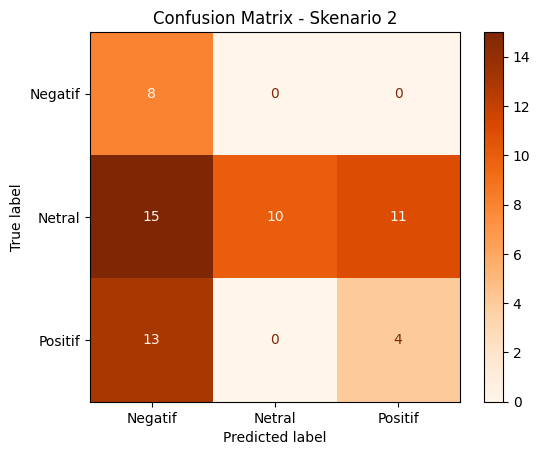

In [12]:
groups = data['komentar_bersih'].factorize()[0]
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(data, y_all, groups))

vec2 = TfidfVectorizer(ngram_range=(1, 2))
X_tr = vec2.fit_transform(data['komentar_bersih'].iloc[tr_idx])
X_te = vec2.transform(data['komentar_bersih'].iloc[te_idx])
y_tr, y_te = y_all[tr_idx], y_all[te_idx]

print('Kalimat unik latih/uji:', len(set(groups[tr_idx])), '/', len(set(groups[te_idx])))
print('Irisan kalimat latih & uji:', len(set(groups[tr_idx]) & set(groups[te_idx])))

svm2 = SVC(kernel='linear', C=1.0, random_state=42).fit(X_tr, y_tr)
y_pr2 = svm2.predict(X_te)
print('\nAkurasi :', round(accuracy_score(y_te, y_pr2), 4))
print(classification_report(y_te, y_pr2, target_names=le.classes_, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pr2), display_labels=le.classes_).plot(cmap='Oranges')
plt.title('Confusion Matrix - Skenario 2'); plt.show()

### 5c. Perbandingan Kernel SVM (validasi silang berkelompok)

In [13]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
hasil = []
for kernel in ['linear', 'rbf', 'poly']:
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), SVC(kernel=kernel, C=1.0))
    skor = cross_val_score(pipe, data['komentar_bersih'], y_all, cv=cv, groups=groups)
    hasil.append({'kernel': kernel, 'rata-rata akurasi': skor.mean().round(4), 'std': skor.std().round(4)})
pd.DataFrame(hasil)

,kernel,rata-rata akurasi,std
0,linear,0.4963,0.2414
1,rbf,0.5103,0.2585
2,poly,0.5827,0.1761


## 6. Uji Prediksi Komentar Baru

In [14]:
def prediksi(kalimat):
    v = vec.transform([preprocess(kalimat)])
    return le.inverse_transform(svm.predict(v))[0]

for k in ['Menunya enak sekali dan bergizi', 'Makanannya dingin dan tidak enak', 'Hari ini ada menu nasi']:
    print(f'{k!r:45} -> {prediksi(k)}')

'Menunya enak sekali dan bergizi'             -> Positif
'Makanannya dingin dan tidak enak'            -> Negatif
'Hari ini ada menu nasi'                      -> Netral


## 7. Kesimpulan
- Data berupa teks komentar (nominal) dengan target sentimen 3 kelas yang seimbang.
- Preprocessing: hapus `id`, case folding, cleaning, tokenisasi, stopword removal (negasi dipertahankan), label encoding, TF-IDF.
- SVM (kernel linear) memberi akurasi sangat tinggi pada pembagian acak, namun hal ini sebagian besar disebabkan kalimat yang berulang (data leakage). Evaluasi berbasis kalimat unik (Skenario 2) memberi gambaran generalisasi yang lebih jujur.
- Untuk penelitian lanjutan disarankan memakai data komentar asli yang lebih beragam.